# Л1 — Підготовка даних

Велика частина роботи в Data Science — збір і підготовка даних. Саме тут виникає багато неочікуваних проблем і пасток.

Ноутбук нижче базово показує, як працювати з даними й готувати їх. Він не охоплює всіх можливих сценаріїв, а приклади в ньому часом сильно спрощені. Проте він дасть розуміння, де шукати помилки і як з ними боротися. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Data Cleaning](https://www.kaggle.com/learn/data-cleaning).

Базовий алгоритм підготовки даних може виглядати так (у дужках — кроки цього ноутбука):

- зчитування даних і початкове дослідження (1);
- дослідження структури й особливостей даних, зміна типів (2);
- об'єднання даних з різних джерел (3–4);
- робота з пропущеними й зламаними значеннями: drop, fill тощо (5, 7, 8);
- пошук outliers: drop, clip тощо (6);
- пошук зайвих і бракуючих колонок (9).

І головне: з кожною дією треба бути обережним. Outliers можуть бути реальними даними, які логічно пояснюються і які не можна видаляти. А пропущені значення можуть щось означати й бути корисними. Обидва випадки є в цій роботі.

Далі бувають кроки, специфічні для певних моделей чи алгоритмів:

- scaling: normalization, standardization тощо;
- обробка категорійних колонок: one-hot encoding тощо;
- dimensionality reduction.

Тут вони не розглядаються, частину з них побачите в Л2 і Л3.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця недоліків — у `README.md`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Завантаження даних

На цьому етапі важливо впевнитися, що файли завантажено правильно, і подивитися, що взагалі всередині. Можуть допомогти `df.head()`, `df.tail()`, `df.shape` і `df.dtypes`.

Що ви маєте зрозуміти?

- Чи зчиталися дані взагалі?
- Чи правильно розпарсилися рядки, колонки й значення?
- Які типи в колонок?
- Які приблизно значення?
- Скільки рядків і колонок?

In [2]:
data_dir = Path("../students/l1-data-prep/variants/6")
df_meters = pd.read_parquet(data_dir / "meters.parquet")
df_registry = pd.read_csv(data_dir / "registry.csv")

print(df_meters.shape, df_registry.shape)
print(df_meters.dtypes, df_registry.dtypes, sep="\n\n")
display(df_registry.head())
df_meters.head()

(525659, 4) (800, 7)
meter_id                      str
ts                 datetime64[us]
consumption_kwh           float64
record_ts          datetime64[us]
dtype: object

meter_id              str
customer_type         str
tariff                str
electric_heating    int64
connection_year     int64
years_connected     int64
district              str
dtype: object


,meter_id,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA100782,small_business,single,0,2022,3,Podil
1,UA100923,small_business,single,0,2015,10,Podil
2,UA102155,household,single,0,1985,41,Darnytsia
3,UA102437,household,dual_zone,1,2014,11,Obolon
4,UA103419,small_business,single,0,2012,14,Darnytsia


,meter_id,ts,consumption_kwh,record_ts
0,UA100782,2026-01-05 00:00:00,0.4393,2026-01-05 00:08:14
1,UA100782,2026-01-05 01:00:00,0.4009,2026-01-05 01:11:25
2,UA100782,2026-01-05 02:00:00,0.3712,2026-01-05 02:09:28
3,UA100782,2026-01-05 03:00:00,0.3548,2026-01-05 03:01:07
4,UA100782,2026-01-05 04:00:00,0.4213,2026-01-05 04:02:12


## 2. Звірка з описом

Іноді бізнес надає опис ідеальних даних, але реальні дані часто з ним не збігаються. Тому спершу подивіться, чи ваші дані відповідають опису в `README.md`. Може допомогти `df.describe()`.

Перевірте (але поки не виправляйте):

- типи колонок: якщо число прочиталося як текст, частина операцій спрацює неправильно;
- скільки рядків мають `customer_type`, `tariff` чи `electric_heating`, яких немає в описі;
- скільки рядків мають `ts`, `connection_year` чи `years_connected` поза межами з опису;
- скільки різних лічильників у кожному файлі — мають бути по 800.

Можуть допомогти `isin`, `between` і `nunique`.

Недоліки з таблиці в `README.md` перевірятимете далі, кожен у своєму кроці. Межі споживання залежать від типу абонента, а тип є лише в реєстрі, тому їх перевірите після об'єднання, на кроці 6.

In [3]:
allowed = {
    "customer_type": ["household", "small_business", "industrial"],
    "tariff": ["single", "dual_zone"],
    "electric_heating": [0, 1],
}
for col, values in allowed.items():
    print(col, "поза описом:", (~df_registry[col].isin(values)).sum())

for col, (lo, hi) in {"connection_year": (1985, 2024), "years_connected": (1, 41)}.items():
    print(col, "поза межами:", (~df_registry[col].between(lo, hi)).sum())

ts_ok = df_meters["ts"].between(pd.Timestamp("2026-01-05 00:00"), pd.Timestamp("2026-02-01 23:00"))
print("ts поза межами:", (~ts_ok).sum())

print("лічильників:", df_meters["meter_id"].nunique(), "у meters,", df_registry["meter_id"].nunique(), "у registry")
print("пропусків:", df_meters.isna().sum().sum(), "у meters,", df_registry.isna().sum().sum(), "у registry")
df_meters.describe()

customer_type поза описом: 0
tariff поза описом: 0
electric_heating поза описом: 0
connection_year поза межами: 0
years_connected поза межами: 0
ts поза межами: 0
лічильників: 800 у meters, 800 у registry
пропусків: 0 у meters, 0 у registry


,ts,consumption_kwh,record_ts
count,525659,525659.000000,525659
mean,2026-01-18 18:32:39.143094,597.140922,2026-01-18 18:55:14.431390
min,2026-01-05 00:00:00,0.031200,2026-01-05 00:01:01
25%,2026-01-11 19:00:00,0.421200,2026-01-11 19:11:47.500000
50%,2026-01-18 15:00:00,0.937200,2026-01-18 15:11:45
75%,2026-01-25 18:00:00,2.823500,2026-01-25 18:05:36
max,2026-02-01 23:00:00,215714.700000,2026-02-02 22:29:32
std,NaN,6161.060668,NaN


## 3. Реєстр: номери й райони (D-E, D-F)

Дані зберігаються в різних системах, тому формат ідентифікатора може не збігатися: `" UA123456"` для pandas — інший номер, ніж `UA123456`. Наївний join призведе до того, що частина даних втратиться. Так само `podil` і `Podil` — різні райони, і будь-який підрахунок по районах буде хибним.

Для D-E і D-F виведіть, скільки рядків реєстру зіпсовано, і виправте їх так, як сказано в таблиці недоліків. Можуть допомогти `str.fullmatch(r"UA\d{6}")`, `isin`, `str.strip()`, `str.lstrip("0")` і `str.capitalize()`.

In [4]:
bad_id = ~df_registry["meter_id"].str.fullmatch(r"UA\d{6}")
print("D-E, зіпсованих номерів:", bad_id.sum())
print(df_registry.loc[bad_id, "meter_id"].head(10).tolist())
df_registry["meter_id"] = df_registry["meter_id"].str.strip().str.lstrip("0")
print("після виправлення:", (~df_registry["meter_id"].str.fullmatch(r"UA\d{6}")).sum(),
      "| різних номерів:", df_registry["meter_id"].nunique())

districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
bad_district = ~df_registry["district"].isin(districts)
print("D-F, районів не як в описі:", bad_district.sum())
# repr, щоб було видно пробіли в кінці
print(df_registry.loc[bad_district, "district"].map(repr).value_counts().to_dict())
df_registry["district"] = df_registry["district"].str.strip().str.capitalize()
print("після виправлення:", (~df_registry["district"].isin(districts)).sum())

D-E, зіпсованих номерів: 96
['UA107278 ', ' UA120854', ' UA128757', '00UA133081', ' UA136121', '00UA142970', '00UA158660', ' UA161770', ' UA166884', ' UA169776']
після виправлення: 0 | різних номерів: 800
D-F, районів не як в описі: 80
{"'SOLOMIANKA'": 13, "'Solomianka '": 8, "'Sviatoshyn '": 8, "'DARNYTSIA'": 6, "'podil'": 6, "'Darnytsia '": 5, "'Podil '": 5, "'Obolon '": 5, "'PODIL'": 4, "'solomianka'": 4, "'OBOLON'": 4, "'obolon'": 4, "'darnytsia'": 3, "'sviatoshyn'": 3, "'SVIATOSHYN'": 2}
після виправлення: 0


## 4. Об'єднання

Тепер погодинні дані можна об'єднати з реєстром за `meter_id` (join, у pandas — `merge`). pandas не попереджає, коли рядок не знайшов пари, тому якість об'єднання треба перевірити самому.

Об'єднану таблицю назвіть `df`, з нею працюватимете далі. Перевірте й виведіть:

- кількість рядків до і після об'єднання — вона не має змінитися;
- кількість рядків без атрибутів абонента (пропуск у `customer_type`) — має бути 0.

Може допомогти `merge(..., how="left", validate="m:1")`: `validate` ще й перевірить, що кожному лічильнику відповідає один рядок реєстру.

In [5]:
df = df_meters.merge(df_registry, on="meter_id", how="left", validate="m:1")
print("рядків до:", len(df_meters), "| після:", len(df))
print("без customer_type:", df["customer_type"].isna().sum())

рядків до: 525659 | після: 525659
без customer_type: 0


## 5. Повторні відправки (D-C)

Повторна відправка — та сама година того самого лічильника ще раз, іноді з уточненим значенням. Якщо лишити обидва записи, споживання за цю годину подвоїться. Лишаємо найпізніший за `record_ts` запис як найсвіжіший.

Виведіть кількість рядків і кількість різних пар `meter_id` і `ts`, потім зніміть повтори. Можуть допомогти `duplicated(["meter_id", "ts"])`, `sort_values("record_ts")` і `drop_duplicates(["meter_id", "ts"], keep="last")`.

In [6]:
key = ["meter_id", "ts"]
print("D-C, рядків:", len(df), "| різних пар meter_id і ts:", len(df[key].drop_duplicates()))
df = df.sort_values("record_ts").drop_duplicates(key, keep="last").reset_index(drop=True)
print("після зняття повторів:", len(df))

D-C, рядків: 525659 | різних пар meter_id і ts: 515402


після зняття повторів: 515402


## 6. Одиниці виміру (D-D)

Значення у Вт·год схожі на викиди, але це не шум, а помилка одиниць. Якщо їх видалити, зникнуть цілі абоненти.

1. Для кожного лічильника порахуйте відношення його медіани `consumption_kwh` до медіани всіх рядків його `customer_type`. Більше 100 — лічильник звітує у Вт·год.
2. Побудуйте графік медіан лічильників за `customer_type` з логарифмічною віссю, наприклад boxplot.
3. Виведіть кількість лічильників у Вт·год, найбільше відношення серед решти лічильників і найменше серед лічильників у Вт·год (якщо таких немає — лише найбільше відношення серед усіх). Ці числа — доказ у звіті: вони показують, наскільки далеко від порога обидві групи.
4. Поділіть значення цих лічильників на 1000 і виведіть, скільки рядків поза межами споживання з опису, — має бути 0.

Можуть допомогти `DataFrame.boxplot(column=..., by="customer_type")`, `plt.yscale("log")` і `between`. Клітинку з діленням не запускайте двічі: значення поділяться ще раз. Якщо так сталося, перезапустіть ноутбук з початку.

поза межами споживання до виправлення: 41003


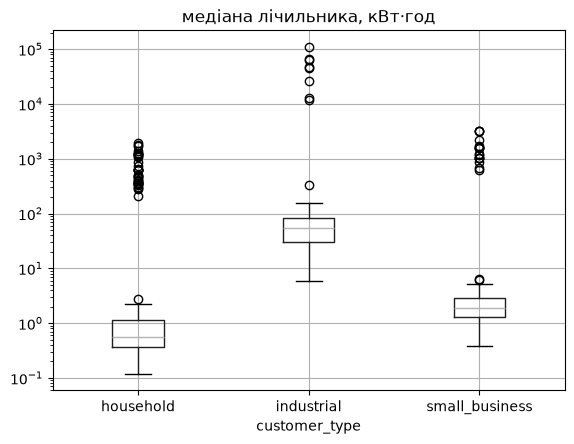

D-D, лічильників у Вт·год: 64
макс. відношення серед решти: 6.59
мін. відношення серед Вт·год: 233.56


поза межами споживання після: 0


In [7]:
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}


def out_of_bounds(data):
    ok = data["consumption_kwh"].between(data["customer_type"].map(min_kwh), data["customer_type"].map(max_kwh))
    return (~ok).sum()


print("поза межами споживання до виправлення:", out_of_bounds(df))

meter_median = df.groupby("meter_id")["consumption_kwh"].median()
meter_type = df.groupby("meter_id")["customer_type"].first()
type_median = df.groupby("customer_type")["consumption_kwh"].median()
ratio = meter_median / meter_type.map(type_median)

pd.DataFrame({"median": meter_median, "customer_type": meter_type}).boxplot(column="median", by="customer_type")
plt.yscale("log")
plt.suptitle("")
plt.title("медіана лічильника, кВт·год")
plt.show()

wh = ratio[ratio > 100].index
print("D-D, лічильників у Вт·год:", len(wh))
print("макс. відношення серед решти:", round(ratio[ratio <= 100].max(), 2))
print("мін. відношення серед Вт·год:", round(ratio[wh].min(), 2))

df.loc[df["meter_id"].isin(wh), "consumption_kwh"] /= 1000
print("поза межами споживання після:", out_of_bounds(df))

## 7. Лічильники, що замовкли (D-A)

Пропуски не заповнюємо: те, що лічильник замовк, уже є інформацією про можливу відмову, а середнє її стерло б. Не видаляємо теж: до відмови лічильник передавав правильні дані.

Для кожного лічильника порахуйте, скільки годин минуло від його останнього `ts` до `2026-02-01 23:00`; більше 48 — замовк. Як на кроці 6, виведіть кількість замовклих, найбільшу тишу серед решти й найменшу серед замовклих (якщо замовклих немає — лише найбільшу тишу серед усіх).

Номери замовклих лічильників збережіть списком `silent`, наприклад `list(....index)`: він знадобиться в регресії.

Можуть допомогти `pd.Timestamp("2026-02-01 23:00")` і `/ pd.Timedelta(hours=1)`.

In [8]:
silence = (pd.Timestamp("2026-02-01 23:00") - df.groupby("meter_id")["ts"].max()) / pd.Timedelta(hours=1)
silent = list(silence[silence > 48].index)

print("D-A, замовклих:", len(silent))
print("макс. тиша серед решти, год:", silence[silence <= 48].max())
print("мін. тиша серед замовклих, год:", silence[silent].min())

D-A, замовклих: 48
макс. тиша серед решти, год: 1.0
мін. тиша серед замовклих, год: 140.0


## 8. Завмерлі лічильники (D-B)

Завмерлі значення виглядають правдоподібно, і ні середнє, ні максимум їх не видають. Помітно лише те, що значення перестали змінюватися. Такі лічильники не видаляємо: частина їхніх годин справна.

Для кожного лічильника порахуйте частку різних значень `consumption_kwh` серед його записів; менше 0.65 — завмер. Побудуйте гістограму цієї частки по лічильниках. Як на кроці 6, виведіть кількість завмерлих, найменшу частку серед решти й найбільшу серед завмерлих (якщо завмерлих немає — лише найменшу частку серед усіх).

Номери завмерлих лічильників збережіть списком `frozen`: він знадобиться в регресії.

Можуть допомогти `nunique()`, `size()` і `plt.hist`.

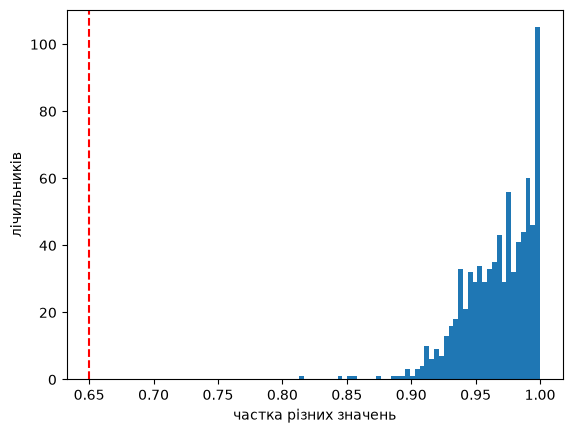

D-B, завмерлих: 0
мін. частка серед усіх: 0.813


In [9]:
by_meter = df.groupby("meter_id")["consumption_kwh"]
share = by_meter.nunique() / by_meter.size()
frozen = list(share[share < 0.65].index)

plt.hist(share, bins=50)
plt.axvline(0.65, color="red", linestyle="--")
plt.xlabel("частка різних значень")
plt.ylabel("лічильників")
plt.show()

print("D-B, завмерлих:", len(frozen))
print("мін. частка серед усіх:", round(share.min(), 4))

## 9. Кореляції

Колонка, що майже копіює іншу, не додає інформації: у кластеризації вона подвоює вагу того самого фактора, а в регресії робить коефіцієнти нестабільними. Технічна колонка `record_ts` після кроку 5 теж не потрібна.

Порахуйте кореляції між числовими колонками об'єднаної таблиці. Пару з кореляцією за модулем понад 0.95 вважайте копією і лиште з неї одну колонку. Приберіть `record_ts`. Підсумкову таблицю назвіть `result`.

Можуть допомогти `select_dtypes("number").corr().abs()` і `drop(columns=...)`.

In [10]:
corr = df.select_dtypes("number").corr()
display(corr.round(3))

pairs = [(col1, col2) for col1 in corr for col2 in corr if col1 < col2 and abs(corr.loc[col1, col2]) > 0.95]
for col1, col2 in pairs:
    print(col1, col2, round(corr.loc[col1, col2], 4))

# years_connected по суті рахується з connection_year, лишаю рік підключення
result = df.drop(columns=["years_connected", "record_ts"])
print(list(result.columns))

,consumption_kwh,electric_heating,connection_year,years_connected
consumption_kwh,1.000,-0.074,-0.001,0.000
electric_heating,-0.074,1.000,0.069,-0.069
connection_year,-0.001,0.069,1.000,-0.999
years_connected,0.000,-0.069,-0.999,1.000


connection_year years_connected -0.999
['meter_id', 'ts', 'consumption_kwh', 'customer_type', 'tariff', 'electric_heating', 'connection_year', 'district']


## 10. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [11]:
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (515402, 8)


## 11. Регресія

Регресію часто використовують, щоб передбачати певні показники. Проте лінійна регресія також показує, як кожен показник впливає на результат. Це і є регресійний аналіз.

Для прикладу подивимося, як на добове споживання домогосподарства впливають електроопалення і двозонний тариф: `y = a + b₁·x₁ + b₂·x₂`.

- `y` — середнє споживання лічильника за добу, кВт·год;
- `x₁` — `electric_heating`, `x₂` — двозонний тариф (обидва 0 або 1);
- `b₁` і `b₂` — на скільки кВт·год на добу більше споживає абонент із цим фактором за однакового іншого;
- `a` — споживання без опалення на звичайному тарифі;
- R² — яку частку розкиду споживання пояснюють обидва фактори, від 0 до 1.

Регресія тут краща за просте порівняння середніх: двозонний тариф здебільшого мають будинки з опаленням, і різниця середніх за тарифом приписала б тарифу ще й споживання на опалення.

Нормалізація не потрібна: обидва фактори мають однаковий масштаб (0 або 1), тож `b₁` і `b₂` можна порівнювати напряму, а `y` лишається в кВт·год на добу, і коефіцієнти легко пояснити. Якби фактори мали різні одиниці, наприклад площу і рік, для порівняння впливу їх спершу стандартизували б.

Лічильники з `silent` і `frozen` не беремо: у `cleaned.parquet` вони лишаються, але їхнє середнє споживання спотворене.

Код майже готовий: допишіть `homes` і запустіть.

In [12]:
homes = result[(result["customer_type"] == "household") & ~(result["meter_id"].isin(silent + frozen))]

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("лічильників:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

лічильників: 490
a = 11.32, b₁ (опалення) = 20.00, b₂ (двозонний тариф) = 2.50, R² = 0.701
